In [1]:
import sys, importlib
sys.path.append("..")

import bbo_utils
importlib.reload(bbo_utils)

#now using bbo_utils to store all my reusable functions
from bbo_utils import *

functions = load_functions()

In [7]:
for i in range(1, 9):
    check_result(i, functions)
    print()

Function 1
Latest: X=[0.75 0.6 ], y=1.8450686723112454e-12
Best:   X=[0.75 0.6 ], y=1.8450686723112454e-12

Function 2
Latest: X=[0.742475 0.177258], y=0.368468164684646
Best:   X=[0.702637 1.      ], y=0.6710529877291967

Function 3
Latest: X=[0.433348 0.528625 0.418951], y=-0.014403518406881257
Best:   X=[0.4255   0.527545 0.422063], y=-0.010242618647230691

Function 4
Latest: X=[0.41 0.44 0.43 0.44], y=0.19927951093333407
Best:   X=[0.43 0.44 0.43 0.42], y=0.34001099086265585

Function 5
Latest: X=[0.005633 0.985666 0.980462 0.996151], y=3944.0708537614914
Best:   X=[0.005633 0.985666 0.980462 0.996151], y=3944.0708537614914

Function 6
Latest: X=[0.437161 0.320742 0.578847 0.762968 0.194246], y=-0.2489550364199761
Best:   X=[0.45433  0.363869 0.508315 0.757164 0.150167], y=-0.2049823948689158

Function 7
Latest: X=[0.154047 0.257312 0.219209 0.266136 0.307656 0.729736], y=2.688767533788612
Best:   X=[0.154047 0.257312 0.219209 0.266136 0.307656 0.729736], y=2.688767533788612

Funct

### Function 1

In [3]:
check_result(1, functions)

Function 1
Latest: X=[0.75 0.6 ], y=1.8450686723112454e-12
Best:   X=[0.75 0.6 ], y=1.8450686723112454e-12


[0.66666667 0.8        0.93333333 0.53333333 0.         0.4
 0.53333333 0.86666667 0.6        0.73333333 0.26666667 0.13333333
 0.06666667 0.2        0.33333333 1.        ]


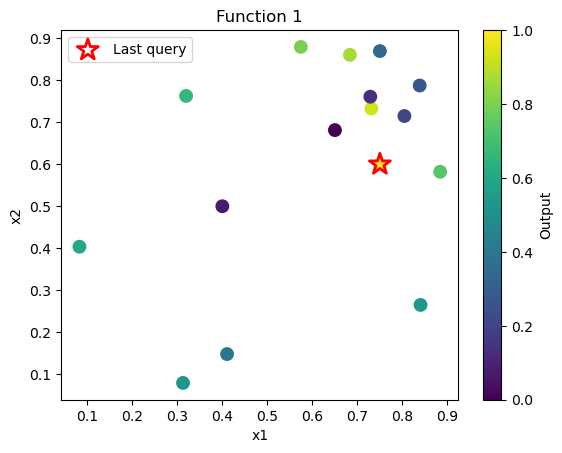

In [4]:
y_scaled = scale_scores(functions[1]["y"])

print(y_scaled)
plot_2d(1, functions, y_scaled)

I am going to be very careful when choosing my next query, as this function seems to be extremely sensitive to small changes. I achieved a very strong result in the previous round, so I now want to focus on exploiting the area around this new best.

#### chosen query for F1

`0.740000-0.610000`

### Function 2

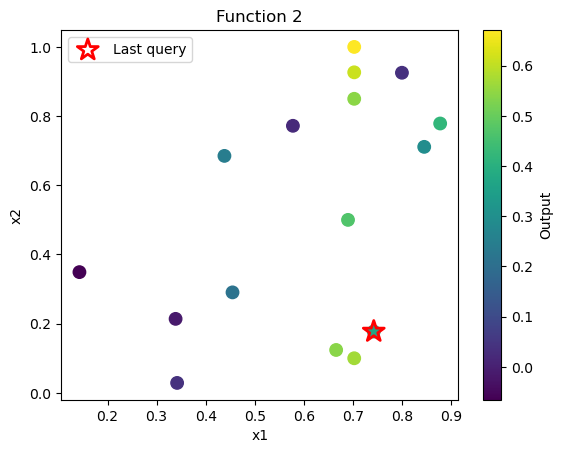

In [8]:
plot_2d(2, functions)

In [9]:
f2_kernel_results = validate_kernels(2, functions)
f2_kernel_results

[(('Matern', 0.1), np.float64(0.17901252279926738)),
 (('RQ', 0.05), np.float64(0.18150286458119297)),
 (('RBF', 0.1), np.float64(0.18212139262425975)),
 (('RQ', 0.1), np.float64(0.18255465260442094)),
 (('RBF', 0.05), np.float64(0.18558555579611186)),
 (('Matern', 0.05), np.float64(0.19175044209151923)),
 (('Matern', 0.2), np.float64(0.2220572366652266)),
 (('RQ', 0.2), np.float64(0.2395948112421234)),
 (('Matern', 0.5), np.float64(0.34664989773334876)),
 (('RBF', 0.2), np.float64(0.4171196925307201)),
 (('RQ', 0.5), np.float64(0.66078719311937)),
 (('RBF', 0.5), np.float64(1.1291935417321721))]

In [10]:
kernel_f2 = Matern(length_scale=0.1)

gp_f2 = fit_gp(2, functions, kernel_f2)

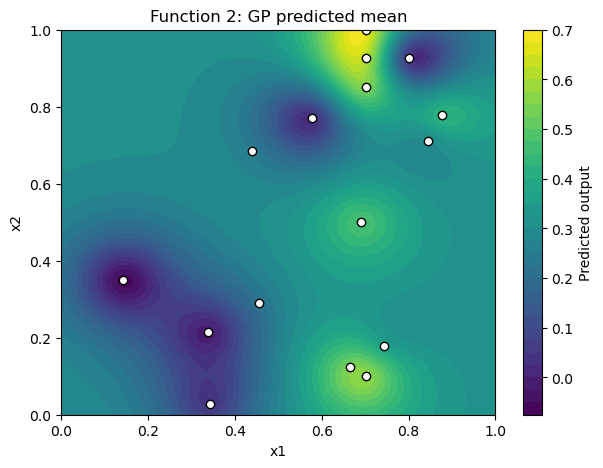

In [11]:
plot_gp_2d(2, gp_f2, functions)

In [16]:
X_candidates = np.array([
    [0.662637, 1.0],
    [0.672637, 1.0],
    [0.682637, 1.0],
    [0.692637, 1.0],
    [0.702637, 1.0],  # Existing observation
    [0.712637, 1.0],
    [0.722637, 1.0],
    [0.732637, 1.0],
    [0.742637, 1.0]
])

mu, sigma = gp_f2.predict(
    X_candidates,
    return_std=True
)

pd.DataFrame({
    "x1": X_candidates[:, 0],
    "x2": X_candidates[:, 1],
    "Predicted Score": mu,
    "Uncertainty": sigma,
    "UCB": mu + 2 * sigma
})

suggestions_f2 = acquisitions(
    gp_f2,
    X_candidates,
    best_y=functions[2]["y"].max()
)

suggestions_f2

{'UCB': array([0.662637, 1.      ]),
 'EI': array([0.662637, 1.      ]),
 'PI': array([0.692637, 1.      ])}

In [17]:
check_uncertainty(gp_f2, suggestions_f2)

UCB: mean=0.6662, uncertainty=0.1252
EI: mean=0.6662, uncertainty=0.1252
PI: mean=0.6851, uncertainty=0.0382


Want to explore candidates with fixed x2 = 0.1 to see if the horizontal region is promising.


#### chosen query for f2

`0.692637, 1.00000`

### Function 3

In [18]:
check_result(3, functions)

Function 3
Latest: X=[0.433348 0.528625 0.418951], y=-0.014403518406881257
Best:   X=[0.4255   0.527545 0.422063], y=-0.010242618647230691


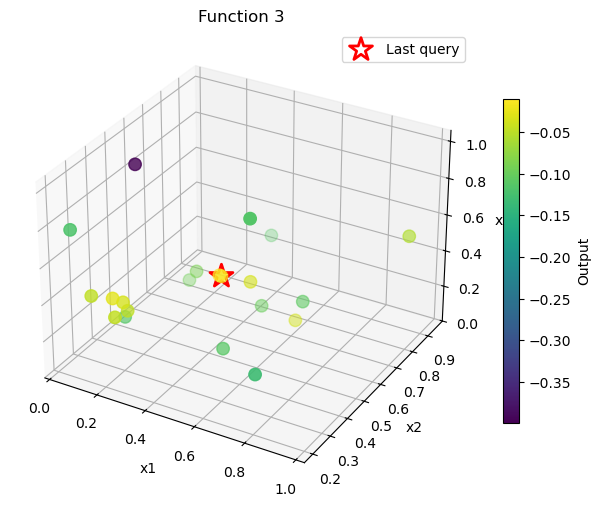

In [19]:
plot_3d(3, functions)

In [20]:
validate_kernels(3, functions)

[(('RQ', 0.1), np.float64(0.03591683538233567)),
 (('Matern', 0.1), np.float64(0.03656284046566029)),
 (('RQ', 0.05), np.float64(0.0367372120857963)),
 (('RBF', 0.05), np.float64(0.03807673252387875)),
 (('Matern', 0.05), np.float64(0.038279021993802724)),
 (('RBF', 0.1), np.float64(0.038305211650818294)),
 (('Matern', 0.2), np.float64(0.04173686832321855)),
 (('RQ', 0.2), np.float64(0.0477820293592599)),
 (('RBF', 0.2), np.float64(0.05494091574134284)),
 (('Matern', 0.5), np.float64(0.07494761772377245)),
 (('RQ', 0.5), np.float64(0.10137856230497645)),
 (('RBF', 0.5), np.float64(0.1568679722844022))]

In [23]:
kernel_f3 = RationalQuadratic(
    length_scale=0.1,
    alpha=1.0
)

gp_f3 = fit_gp(3, functions, kernel_f3)

In [40]:
np.random.seed(42)

X_candidates = np.random.uniform(
    0, 1,
    size=(100000, 3)
)

suggestions_f3 = acquisitions(
    gp_f3,
    X_candidates,
    best_y=functions[3]["y"].max()
)

suggestions_f3

{'UCB': array([0.48025777, 0.6210419 , 0.5059692 ]),
 'EI': array([0.4380833 , 0.60582108, 0.44723081]),
 'PI': array([0.43334824, 0.52862525, 0.41895086])}

In [43]:
check_uncertainty(gp_f3, suggestions_f3)

UCB: mean=-0.0539, uncertainty=0.0663
EI: mean=-0.0291, uncertainty=0.0498
PI: mean=-0.0098, uncertainty=0.0063


In [44]:
query_f3 = suggestions_f3["PI"]
format_query(query_f3)

'0.433348-0.528625-0.418951'

The huge improvement last round makes me eager to know whether I have found an optimum, so I want to exploit the point this round

#### chosen query for f3

`0.433348-0.528625-0.418951`

### Function 4

In [53]:
check_result(4, functions)

Function 4
Latest: X=[0.43 0.44 0.43 0.42], y=0.34001099086265585
Best:   X=[0.43 0.44 0.43 0.42], y=0.34001099086265585


In [50]:
validate_kernels(4, functions)

[(('RQ', 0.5), np.float64(1.5837675149720112)),
 (('Matern', 0.5), np.float64(2.000124148233155)),
 (('RBF', 0.5), np.float64(2.214528567905537)),
 (('RQ', 0.2), np.float64(2.6518090584346043)),
 (('RBF', 0.2), np.float64(3.057143031554619)),
 (('Matern', 0.2), np.float64(3.150672349308287)),
 (('RQ', 0.1), np.float64(3.5431282008295124)),
 (('RBF', 0.1), np.float64(4.24871074896228)),
 (('Matern', 0.1), np.float64(4.401904521324633)),
 (('RQ', 0.05), np.float64(4.720857324466919)),
 (('Matern', 0.05), np.float64(5.657373388211198)),
 (('RBF', 0.05), np.float64(5.679818896950227))]

In [52]:
best_kernel_f4 = RationalQuadratic(length_scale=0.5)
gp_f4 = fit_gp(4, functions, best_kernel_f4)

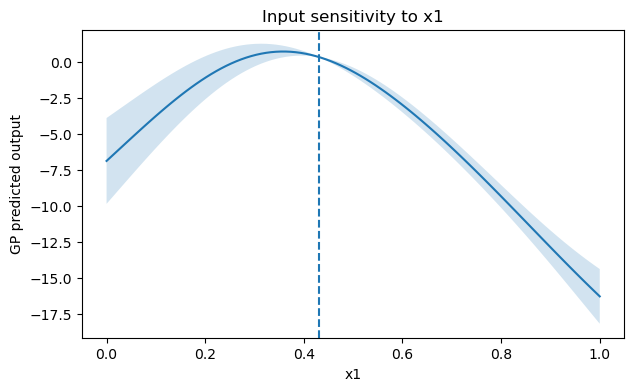

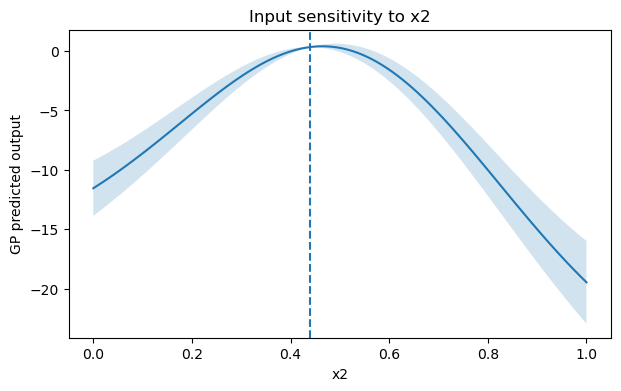

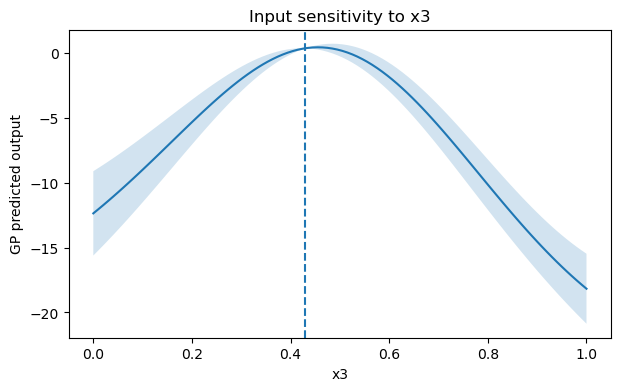

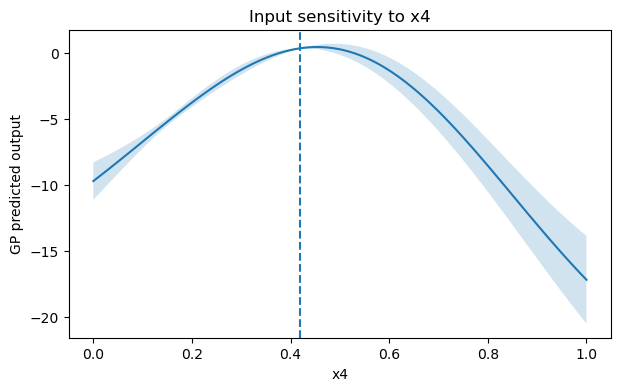

In [58]:
best_idx = np.argmax(functions[4]["y"])
best_x_f4 = functions[4]["X"][best_idx]

plot_input_sensitivity(gp_f4, best_x_f4)

In [63]:
# candidates around the new F4 best
# exploring slightly lower x1 and slightly higher x4

candidates_f4 = np.array([
    [0.42, 0.44, 0.43, 0.42],  # decrease x1
    [0.41, 0.44, 0.43, 0.42],  # decrease x1 further
    [0.43, 0.44, 0.43, 0.43],  # increase x4
    [0.43, 0.44, 0.43, 0.44],  # increase x4 further
    [0.42, 0.44, 0.43, 0.43],  # decrease x1 + increase x4
    [0.41, 0.44, 0.43, 0.44]   # stronger combined adjustment
])

mean, std = gp_f4.predict(candidates_f4, return_std=True)

for point, m, s in zip(candidates_f4, mean, std):
    print(
        f"{point} -> "
        f"mean={m:.4f}, uncertainty={s:.4f}"
    )

[0.42 0.44 0.43 0.42] -> mean=0.4360, uncertainty=0.0499
[0.41 0.44 0.43 0.42] -> mean=0.5183, uncertainty=0.1019
[0.43 0.44 0.43 0.43] -> mean=0.3860, uncertainty=0.0463
[0.43 0.44 0.43 0.44] -> mean=0.4165, uncertainty=0.0944
[0.42 0.44 0.43 0.43] -> mean=0.4843, uncertainty=0.0392
[0.41 0.44 0.43 0.44] -> mean=0.6032, uncertainty=0.0832


In [64]:
query_f4 = np.array([0.41, 0.44, 0.43, 0.44])

format_query(query_f4)

'0.410000-0.440000-0.430000-0.440000'

#### chosen query for f4

`0.410000-0.440000-0.430000-0.440000`

### Function 5

Function 5
Latest: X=[0.1     1.      0.99863 0.96   ], y=3915.682001600844
Best:   X=[0.1     1.      0.99863 0.96   ], y=3915.682001600844


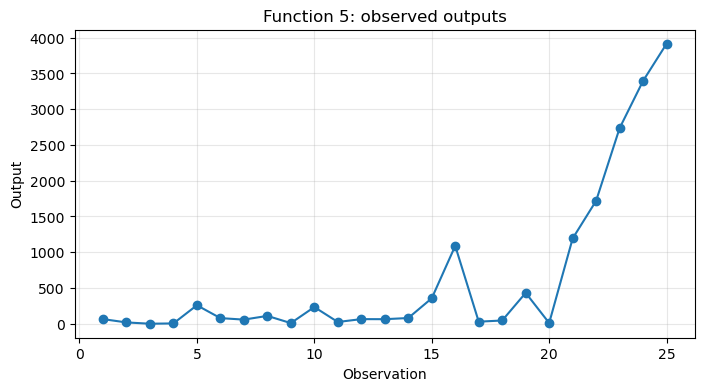

[(('RQ', 0.5), np.float64(70.05133358293014)),
 (('Matern', 0.5), np.float64(78.81312366266341)),
 (('RQ', 0.2), np.float64(130.7975997350442)),
 (('RBF', 0.5), np.float64(142.32749110952608)),
 (('Matern', 0.2), np.float64(259.41902003608106)),
 (('RBF', 0.2), np.float64(269.87084528725313)),
 (('RQ', 0.1), np.float64(285.67897407520513)),
 (('RBF', 0.1), np.float64(469.1083835067774)),
 (('Matern', 0.1), np.float64(482.2331823931843)),
 (('RQ', 0.05), np.float64(485.0404758264673)),
 (('RBF', 0.05), np.float64(614.2262478536194)),
 (('Matern', 0.05), np.float64(637.5306234131765))]

In [65]:
check_result(5, functions)
plot_scores(5, functions)

validate_kernels(5, functions)

In [66]:
kernel_f5 = RationalQuadratic(
    length_scale=0.5,
    alpha=1.0
)

gp_f5 = fit_gp(5, functions, kernel_f5)

In [67]:
np.random.seed(42)

X_candidates = np.random.uniform(
    0, 1,
    size=(100000, 4)
)

suggestions_f5 = acquisitions(
    gp_f5,
    X_candidates,
    best_y=functions[5]["y"].max()
)

suggestions_f5

{'UCB': array([0.00563328, 0.98566602, 0.98046164, 0.99615079]),
 'EI': array([0.00563328, 0.98566602, 0.98046164, 0.99615079]),
 'PI': array([0.00563328, 0.98566602, 0.98046164, 0.99615079])}

In [68]:
check_uncertainty(gp_f5, suggestions_f5)

UCB: mean=4062.4408, uncertainty=100.2651
EI: mean=4062.4408, uncertainty=100.2651
PI: mean=4062.4408, uncertainty=100.2651


In [71]:
query_f5 = suggestions_f5["UCB"]
format_query(query_f5)

'0.005633-0.985666-0.980462-0.996151'

#### chosen query for f5

`0.005633-0.985666-0.980462-0.996151`

### Function 6

Function 6
Latest: X=[0.472234 0.375648 0.509204 0.744126 0.15149 ], y=-0.27842358336452844
Best:   X=[0.45433  0.363869 0.508315 0.757164 0.150167], y=-0.2049823948689158


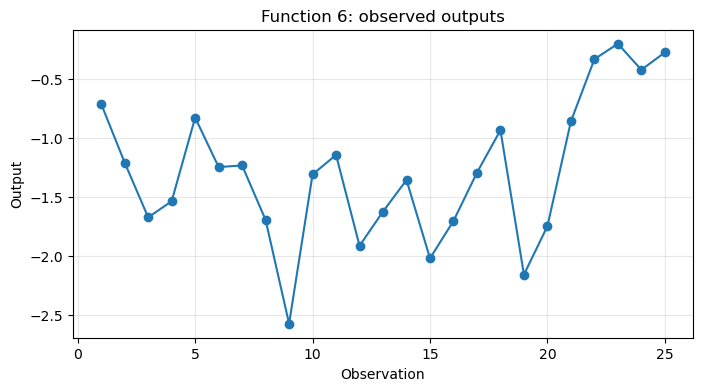

[(('RQ', 0.2), np.float64(0.23712483310113608)),
 (('Matern', 0.5), np.float64(0.25333289615423027)),
 (('RQ', 0.5), np.float64(0.2590172665494669)),
 (('Matern', 0.2), np.float64(0.2902025520500654)),
 (('RBF', 0.2), np.float64(0.2971016793965595)),
 (('RQ', 0.1), np.float64(0.3122833534529052)),
 (('RBF', 0.1), np.float64(0.3693881686941738)),
 (('Matern', 0.1), np.float64(0.37348482000067634)),
 (('RQ', 0.05), np.float64(0.37584133325309127)),
 (('RBF', 0.05), np.float64(0.41687816805685385)),
 (('Matern', 0.05), np.float64(0.41934000770307184)),
 (('RBF', 0.5), np.float64(0.42319464358414804))]

In [72]:
check_result(6, functions)
plot_scores(6, functions)

validate_kernels(6, functions)

#### trying a new strategy for F6 since GP is performing consistently poorly - SVR

In [73]:
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneOut, cross_val_score

X = functions[6]["X"]
y = functions[6]["y"]

svr_models = {
    "RBF C=1": SVR(kernel="rbf", C=1),
    "RBF C=10": SVR(kernel="rbf", C=10),
    "RBF C=100": SVR(kernel="rbf", C=100),
}

for name, svr in svr_models.items():

    model = make_pipeline(
        StandardScaler(),
        svr
    )

    mae = -cross_val_score(
        model,
        X,
        y,
        cv=LeaveOneOut(),
        scoring="neg_mean_absolute_error"
    ).mean()

    print(f"{name}: MAE={mae:.4f}")

RBF C=1: MAE=0.1667
RBF C=10: MAE=0.1556
RBF C=100: MAE=0.1556


| Model | LOOCV MAE |
|---|---:|
| GP (RQ, 0.2) | 0.2371 |
| SVR (RBF, C=1) | 0.1667 |
| **SVR (RBF, C=10)** | **0.1556** |
| SVR (RBF, C=100) | 0.1556 |


SVR substantially performs better than GP, so it is worth trying this round 

In [74]:
svr_f6 = make_pipeline(
    StandardScaler(),
    SVR(kernel="rbf", C=10)
)

svr_f6.fit(
    functions[6]["X"],
    functions[6]["y"]
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('svr', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value
"mean_ mean_: ndarray of shape (n_features,) or NoneThe mean value for each feature in the training set.Equal to ``None`` when ``with_mean=False`` and ``with_std=False``.","ndarray[float64](5,)","[0.53,0.51,0.49,0.58,0.37]"


In [75]:
np.random.seed(42)

X_candidates_f6 = np.random.uniform(
    0, 1,
    size=(100000, 5)
)

predictions_f6 = svr_f6.predict(X_candidates_f6)

best_idx = np.argmax(predictions_f6)

svr_query_f6 = X_candidates_f6[best_idx]
svr_prediction_f6 = predictions_f6[best_idx]

print("Suggested point:", svr_query_f6)
print("Predicted output:", svr_prediction_f6)

Suggested point: [0.43716102 0.32074206 0.578847   0.76296834 0.19424647]
Predicted output: -0.33166862555403176


In [76]:
best_idx_f6 = np.argmax(functions[6]["y"])
best_x_f6 = functions[6]["X"][best_idx_f6]
best_y_f6 = functions[6]["y"][best_idx_f6]

pred_best_f6 = svr_f6.predict(
    best_x_f6.reshape(1, -1)
)[0]

print("Current best point:", best_x_f6)
print("Actual output:", best_y_f6)
print("SVR prediction:", pred_best_f6)

Current best point: [0.45433  0.363869 0.508315 0.757164 0.150167]
Actual output: -0.2049823948689158
SVR prediction: -0.30497187713678087


In [78]:
format_query(svr_query_f6)

'0.437161-0.320742-0.578847-0.762968-0.194246'

this shows the SVR underestimates performance of its chosen points, so i am going to take the risk and choose it's suggested point this round to see if any improvement occurs

#### chosen query for f6

`0.437161-0.320742-0.578847-0.762968-0.194246`

### Function 7

Function 7
Latest: X=[0.077645 0.20753  0.10964  0.277633 0.165312 0.711951], y=1.7644348120750581
Best:   X=[0.174163 0.270107 0.182087 0.25951  0.282083 0.718177], y=2.607862873045956


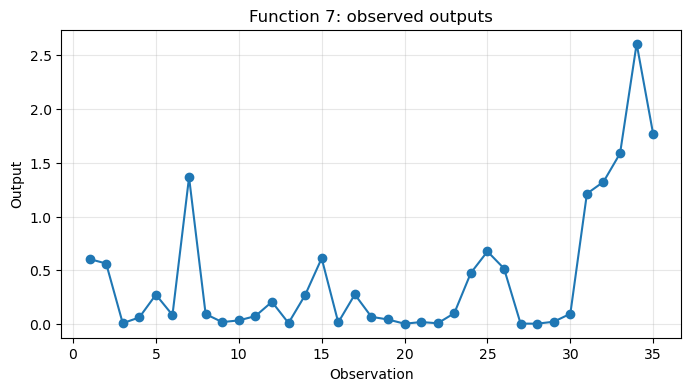

[(('RQ', 0.2), np.float64(0.22179473180767864)),
 (('RQ', 0.5), np.float64(0.2269951652103613)),
 (('Matern', 0.5), np.float64(0.23219399832659157)),
 (('Matern', 0.2), np.float64(0.27210585371728496)),
 (('RBF', 0.2), np.float64(0.27457237033273174)),
 (('RQ', 0.1), np.float64(0.2998592141811738)),
 (('RBF', 0.5), np.float64(0.3637443284272448)),
 (('Matern', 0.1), np.float64(0.3767236616809872)),
 (('RBF', 0.1), np.float64(0.3770755442467003)),
 (('RQ', 0.05), np.float64(0.38546697759613036)),
 (('RBF', 0.05), np.float64(0.4446736751992817)),
 (('Matern', 0.05), np.float64(0.445523345652172))]

In [79]:
check_result(7, functions)
plot_scores(7, functions)

validate_kernels(7, functions)

In [80]:
kernel_f7 = RationalQuadratic(
    length_scale=0.2,
    alpha=1.0
)

gp_f7 = fit_gp(7, functions, kernel_f7)

In [86]:
#generating candidates around current best - 0.08 around

np.random.seed(42)

best_x_f7 = functions[7]["X"][np.argmax(functions[7]["y"])]

X_candidates_f7 = best_x_f7 + np.random.normal(
    loc=0,
    scale=0.08,
    size=(100000, 6)
)

X_candidates_f7 = np.clip(X_candidates_f7, 0, 1)

suggestions_f7 = acquisitions(
    gp_f7,
    X_candidates_f7,
    best_y=functions[7]["y"].max()
)

suggestions_f7

{'UCB': array([0.16783085, 0.22170395, 0.25156711, 0.23958776, 0.2916333 ,
        0.73559141]),
 'EI': array([0.15404687, 0.25731214, 0.21920913, 0.26613616, 0.30765566,
        0.72973618]),
 'PI': array([0.18901656, 0.26695815, 0.18312252, 0.26445255, 0.29247593,
        0.72299636])}

In [83]:
check_uncertainty(gp_f7, suggestions_f7)

UCB: mean=2.3940, uncertainty=0.2548
EI: mean=2.5425, uncertainty=0.1532
PI: mean=2.5983, uncertainty=0.0541


In [85]:
query_f7 = suggestions_f7["EI"]
format_query(query_f7)

'0.154047-0.257312-0.219209-0.266136-0.307656-0.729736'

#### chosen query for f7

`0.154047-0.257312-0.219209-0.266136-0.307656-0.729736`

I would have chosen the PI suggestion for tighter exploitation, but I think it is still too early to focus this closely on the current best. Instead, I chose a point that explores around the best-performing region while still remaining relatively close to it.

### Function 8

Function 8
Latest: X=[0.105481 0.269158 0.077575 0.241274 0.445941 0.627114 0.326085 0.673392], y=9.8579948536101
Best:   X=[0.105481 0.269158 0.077575 0.241274 0.445941 0.627114 0.326085 0.673392], y=9.8579948536101


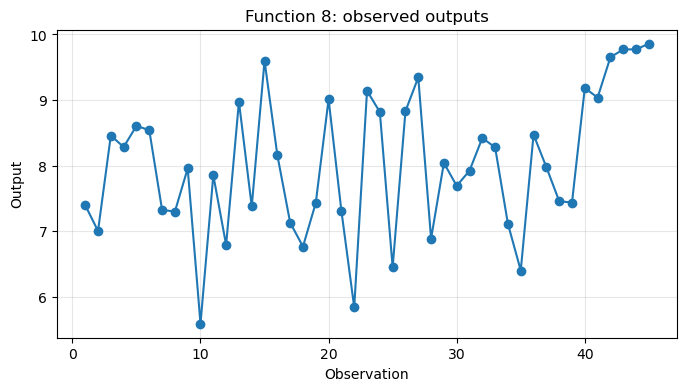

[(('RQ', 0.5), np.float64(0.3377839508630335)),
 (('RBF', 0.5), np.float64(0.39040481709624764)),
 (('Matern', 0.5), np.float64(0.4080127793361666)),
 (('RQ', 0.2), np.float64(0.5392238683233749)),
 (('RQ', 0.1), np.float64(0.6661714392086546)),
 (('Matern', 0.2), np.float64(0.6817330955117517)),
 (('RBF', 0.2), np.float64(0.6899516102603199)),
 (('RBF', 0.1), np.float64(0.7483951970057882)),
 (('RQ', 0.05), np.float64(0.7494220708000504)),
 (('Matern', 0.1), np.float64(0.7536434566714577)),
 (('RBF', 0.05), np.float64(0.7936183428399364)),
 (('Matern', 0.05), np.float64(0.7974181012817156))]

In [87]:
check_result(8, functions)
plot_scores(8, functions)

validate_kernels(8, functions)

In [88]:
kernel_f8 = RationalQuadratic(
    length_scale=0.5,
    alpha=1.0
)

gp_f8 = fit_gp(8, functions, kernel_f8)

In [89]:
np.random.seed(42)

X_candidates_f8 = np.random.uniform(
    0, 1,
    size=(200000, 8)
)

suggestions_f8 = acquisitions(
    gp_f8,
    X_candidates_f8,
    best_y=functions[8]["y"].max()
)

suggestions_f8

{'UCB': array([0.23558304, 0.30840808, 0.01693813, 0.2434915 , 0.77804682,
        0.3380895 , 0.30489123, 0.33488494]),
 'EI': array([0.1896127 , 0.30123785, 0.06089952, 0.4481168 , 0.66981612,
        0.50320636, 0.38640312, 0.37532953]),
 'PI': array([0.141618  , 0.39460673, 0.10984133, 0.35196213, 0.52636373,
        0.5302087 , 0.32156012, 0.40440353])}

In [90]:
check_uncertainty(gp_f8, suggestions_f8)

UCB: mean=9.5503, uncertainty=0.7149
EI: mean=9.7570, uncertainty=0.5806
PI: mean=9.8408, uncertainty=0.4544


In [91]:
query_f8 = suggestions_f8["PI"]
format_query(query_f8)

'0.141618-0.394607-0.109841-0.351962-0.526364-0.530209-0.321560-0.404404'

#### chosen query for f8

`0.141618-0.394607-0.109841-0.351962-0.526364-0.530209-0.321560-0.404404`

GP has been performing well, so I trust its chosen point and predicted mean - the aim is to keep improving on the current best 